# FRBayes tutorial

This notebook fits the example burst in `examples/data/` from start to finish:

1. choose the device (GPU or CPU),
2. load the de-dispersed burst and prepare it for fitting, apply downsampling,
3. build the pulse model and its priors,
4. as a demonstration, find the maximum likelihood fit with a fixed number of pulses, 
5. perform an iterative greedy search for the most significant features in the data, using the maximum likelihood fits with increasing numbers of pulses,
6. use the result of the iterative search as a warm start for an MCMC algorithm to perform Bayesian inference - we sample the posterior with NUTS and then visualize the result and print some diagnostics,
7. save the fit result.

Each step explains what the code does and some of the many possible choices you have when running an analysis. Every function's docstring has the full list of its arguments.

GPU running is highly recommended --- much of FRBayes is designed specifically to run on Nvidia GPUs, and the code is not guaranteed to run quickly or correctly on other architectures.

## 1. Choose the device

JAX, the library FRBayes computes with, fixes the devices it uses when it starts, so the device has
to be chosen before anything imports it. `use_device("auto")` picks the GPU if one is usable and the
CPU otherwise; `"gpu"` or `"cpu"` forces one. To switch devices, you must restart the kernel.

By default JAX reserves 75% of the GPU's memory when it starts; the line below reserves 20% instead,
which is enough here and leaves room for other work on the same GPU.

In [1]:
from frbayes.devices import use_device
use_device("auto")        # "auto" | "gpu" | "cpu"  (restart the kernel to switch)

import os
# os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false") # If sharing GPU with other processes
os.environ.setdefault("XLA_PYTHON_CLIENT_MEM_FRACTION", "0.2") # share of GPU memory JAX reserves - if not set, JAX automatically grabs 75% of the GPU's total memory, which can be excessive
# os.environ["XLA_FLAGS"] = (os.environ.get("XLA_FLAGS", "") + " --xla_gpu_deterministic_ops=true").strip() #force deterministic computation on GPU

import jax
print(jax.devices())      # e.g. [CudaDevice(id=0)] for the GPU

# jax.config.update("jax_log_compiles", True) # diagnostics for tracking compilation times of jax code

FRBayes: running on the GPU
[CudaDevice(id=0)]


## 2. Imports

**The order of the imports matters: import NumPyro before ArviZ, as below.** In at least one setup,
importing ArviZ first left NumPyro only partly loaded, and the first fit then failed deep inside
NumPyro with `AttributeError: module 'numpyro.distributions' has no attribute 'distribution'`. We
have not pinned down the cause. A likely one is that ArviZ, which can convert NumPyro results,
starts importing NumPyro itself, that import stops part-way, and the second import that follows
does not reconnect one of NumPyro's parts. Importing NumPyro first avoids it. If you see that error,
restart the kernel and check the order. (As in step 1, `use_device` must still come before
anything that imports JAX.)

In [2]:
from pathlib import Path

import numpyro
import numpyro.distributions as dist   # for changing a prior (step 6)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import arviz as az
import arviz_base
import arviz_plots as azp

from frbayes.data import prepare_burst
from frbayes.model import setup_model, running_power_law_log_sed
from frbayes.run import set_priors, run_maxL, run_maxL_iterative, run_NUTS
from frbayes.postprocess import pointwise_log_lik, order_pulses, group_chains, PAIR_SITES
from frbayes.plotting import (plot_burst_TD, plot_burst_FD, plot_noise_window, model_from_draw,
                              plot_fit_TD)
from frbayes.results import save_run, load_run, check_data_unchanged

## 3. Load a burst and prepare it

The burst is an `.npz` file holding the dynamic spectrum `power` (channels × time), the
channel frequencies `freq` in MHz and the sample times `time` in seconds, already dedispersed and with
bad channels removed, and optionally how it was dedispersed (see step 11). This one,
FRB 20181221A (CHIME/FRB event 23438043), a single scattered pulse with a narrow spectrum, was made
from CHIME/FRB baseband data with `dedisperse_baseband.ipynb` in this folder.

`prepare_burst` turns the data file into what the FRBayes fit needs:

1. **Channels.** It sorts the channels by frequency and averages every `n_avg` neighbouring channels
   into one block. Larger `n_avg` means fewer, less noisy channels and faster fits, at the cost of
   frequency resolution. In general, we recommend aggressive downsampling in channels, as most FRBs
   have broad support along the channels and also higher downsampling leads to dramatic speed-up of
   the code. We suggest that downsampling to retain only ~50-100 channels is safe for most signals and
   computationally efficient.
2. **Noise.** It measures each block's noise level as the standard deviation over a stretch of data
   before the burst, the *noise window*. With `toa` provided (a rough arrival time in seconds) the window ends
   a little before the toa (`exclude_fraction` of the lead-in is left out); with `toa=None` the noise level is computed with the first
   `noise_fraction` amount of the segment. The window must contain no burst signal or else the noise estimate will be biased; plot the noise window in step 4.
3. **Fourier transform.** The fit works in the *Fourier domain*: each frequency channel block's time series is
   decomposed into sine waves of different frequencies (the *Fourier frequencies*, in Hz or kHz, not
   to be confused with the radio frequency of a channel). There the pulse model has an exact formula,
   and, for white noise, the noise in different Fourier bins is independent. A pulse of width
   $\sigma$ has a Fourier amplitude that falls as $e^{-2\pi^2\sigma^2 f^2}$, so it has little power
   at Fourier frequencies $f$ well above $1/(2\pi\sigma)$, and the highest bins hold mostly noise.
   `fd_downsample` keeps the lowest $1/\texttt{fd\_downsample}$ of the bins, which speeds up the fit.
   Too large a value would cut off narrow structure; the printed "Fourier truncation" line compares
   the burst's signal with the bins kept and with every bin. The zero frequency (each block's average level, which the fit does not use) and the very
   highest bin are always dropped.
4. **Reference frequency.** A search for excess power in boxes of channels × time finds where the
   burst is. The channels' signal in those boxes then is used to set the reference frequency $\nu_{\rm ref}$, at
   which arrival times, scattering times and spectra are defined. The reference is chosen so that, weighted by
   that signal, the dispersion delay averages to zero, which minimizes correlations between DM and time of arrival.

In [3]:
DATA = Path("../data")       # examples/data, next to this notebook

event_id = "23438043_BB"     # FRB 20181221A: single pulse, narrow spectrum, scattered
# event_id = "43456869_BB"     # FRB 20190710A

burst = prepare_burst(
    path=DATA / f"event_{event_id}.npz",
    event_id=event_id,
    n_avg=16,                                         # raw channels averaged into each block
    fd_downsample=8,                                  # keep the lowest 1/fd_downsample of the Fourier bins
    toa=None,                                         # rough arrival time (s); None: noise from the start of the segment
    noise_fraction=0.2,                               # share of the segment used for the noise when toa is None
    verbose=True,
)

dedispersed with DM 316.327 pc cm^-3 to 400 MHz
807 good channels -> 50 blocks of 16 (7 dropped); block span median 6.641 MHz, max 36.719 MHz
noise estimated from 33 of 165 time bins (first 20% of the segment)
Fourier truncation: keeping 9 of 83 bins (up to 0.7 kHz of 6.1 kHz)
reference frequency 515.7 MHz (channels weighted by their signal in 3 significant box(es); weighted mean 517.9 MHz)
Fourier truncation, estimated with the box search of the data: SNR in its 3 significant box(es) 86.6 with the kept bins, 90.2 with every bin (self-noise raises the second too)


## 4. Look at the data

- `plot_burst_TD`: the dynamic spectrum in time, with the sum over channels above and the fluence
  of each channel to the right. Grey rows are bad channels.
- `plot_burst_FD`: the same data in the Fourier domain, *whitened* (each value divided by its noise
  level, so pure noise sits around 1). The burst should sit at the low Fourier frequencies on the
  left; the right edge is where `fd_downsample` cut.
- `plot_noise_window`: the noise window shaded. If any burst signal falls inside it, the noise is
  overestimated: set `toa` or a smaller `noise_fraction` in step 3.

rebaseline: each channel's noise-window mean subtracted, for display only.


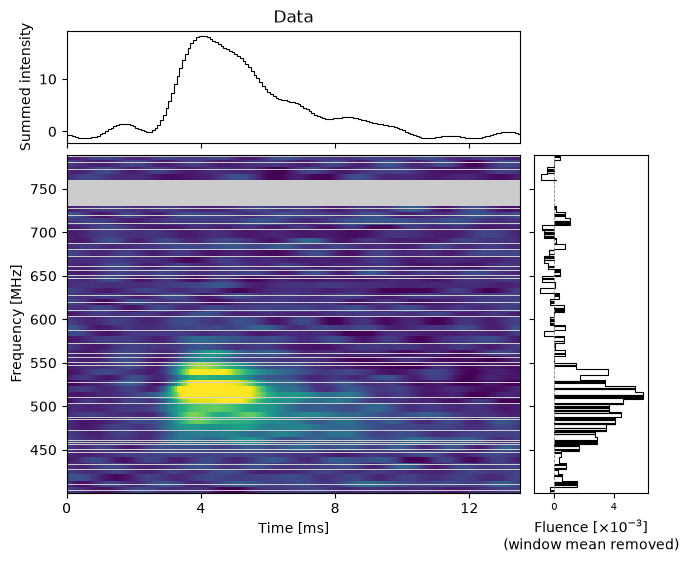

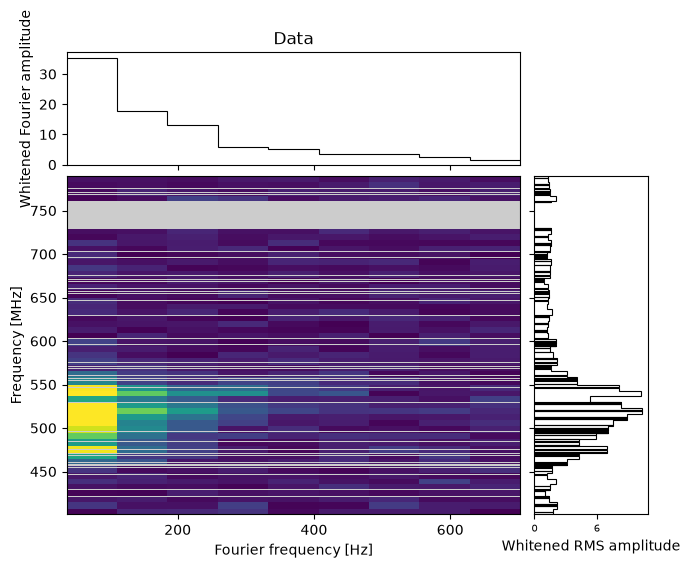

noise window: first 33 of 165 samples (to 2.70 ms)
  profile mean over the last third of the window, less the window mean: +2.77 standard errors (emission leaking in shows as clearly positive)
  profile sd in the window: 1.17   in the last 20% of the segment: 1.33   (expect 1)


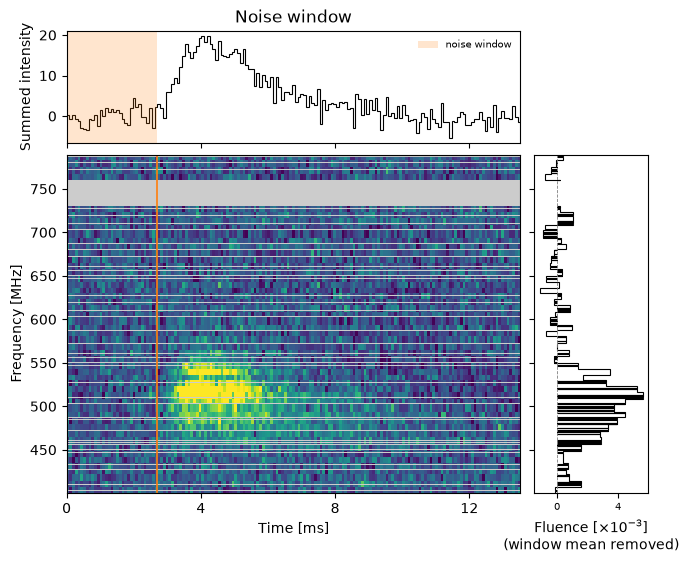

In [4]:
plot_burst_TD(burst);
plot_burst_FD(burst);
plot_noise_window(burst);

## 5. Build the model

Each pulse is

- a **Gaussian in time**, with arrival time $t$ (at $\nu_{\rm ref}$) and width $\sigma$;
- **dispersed** by a residual DM, the small correction to the DM the data were dedispersed with;
- **scattered**: convolved with a one-sided exponential tail of timescale
  $\tau(\nu) = \tau_{\rm ref}\,(\nu/\nu_{\rm ref})^{\delta}$, with $\delta = -4$ by default;
- **smeared** within each channel by the appropriate dispersion measure;
- **averaged over each time sample**: each data sample is the signal averaged over its time bin of
  width $dt$, not its value at one instant, so the model is averaged the same way. In the Fourier
  domain that averaging multiplies the template by the time bin's transfer function,
  $\mathrm{sinc}(f\,dt)\,e^{i\pi f\,dt}$, which matters when a pulse is only a few samples wide;
- given a **spectrum** $\ln F(\nu) = \gamma x + \beta x^2$ with $x = \ln(\nu/\nu_{\rm ref})$, a power
  law of slope $\gamma$ at $\nu_{\rm ref}$ bent by the curvature $\beta$ ($\beta < 0$ gives a peaked
  spectrum, and the more negative $\beta$, the narrower the peak);
- scaled by its **fluence**, fitted in units of the signal-to-noise ratio (SNR) it would have.

By default the pulses share one residual DM and one $\tau_{\rm ref}$, under the assumption that all of a burst's pulses
pass through the same plasma.

`setup_model` builds this model on the burst's channels and Fourier bins. Its constants:

- `freq_channels_ref`: $\nu_{\rm ref}$ from step 3.
- `DM_incoherent`: 0 for coherently dedispersed data (expected for baseband data), where only the fitted
  residual DM smears within a channel; for incoherently dedispersed data, the DM that was removed.
- `freq_members`, `raw_channel_width`: the raw channels in each block and their width, so the smearing
  follows the channels that were averaged, gaps from bad channels included.
- `det_response`: the instrument's response, multiplying the spectrum; 1 if not used.

In [5]:
constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,                   # 0 for coherently dedispersed data
    "freq_members": burst.freq_members,     # raw channels averaged into each block, for the smearing
    "raw_channel_width": burst.raw_dnu,     # width of one raw channel (MHz)
    "det_response": 1.0,                    # instrument response; 1 if not used
}
single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=running_power_law_log_sed,
    fourier_freqs=burst.fourier_freqs,
)

## 6. Priors

A *prior* is the range of values each parameter may take before looking at the data. `set_priors`
derives them from the data window, and prints them:

- arrival time: uniform over the window;
- residual DM: uniform, up to the DM that would sweep the pulse across half the window over the band;
- width $\sigma$: log-uniform, from the narrowest width the kept Fourier bins resolve to a width that
  fits in the window;
- $\tau_{\rm ref}$: uniform from 0 (no scattering) to the longest tail that fits in the window at the
  bottom of the band;
- $\beta$: uniform over `beta_range`, by default $(-200, 10)$, from previous FRB catalogues;
- $\gamma$: uniform over $(-\gamma_{\max}, \gamma_{\max})$ with
  $\gamma_{\max} = 2|\beta_{\min}|\ln(\nu_{\rm top}/\nu_{\rm bot})$ from the telescope's `band`, so
  that a spectrum of any allowed width can peak anywhere in the band. It uses the full band, not the
  channels that survived data conditioning, so it is the same for every burst;
- fluence: half-normal in SNR units, of scale `s_opt`.

Two more choices are printed with them: $\delta$, fixed at $-4$ unless you give it a prior, and the
*repulsion* prior, a soft wall that keeps every pair of pulses apart by about their combined widths
(scattering tail included), so that two overlapping pulses cannot soak up misfit together.

To change a prior, pass it by name, e.g. `set_priors(..., delta=dist.Uniform(-5.0, -3.0))` (with
`import numpyro.distributions as dist`) to fit the scattering index too.

In [6]:
BAND = (400.0, 800.0)     # the telescope's band (MHz): CHIME
priors = set_priors(burst, single_pulse_fn, s_opt=100.0, band=BAND, verbose=True)

mean_arrival_time: Uniform(low=0, high=0.0134349)
DM: Uniform(low=-0.361228, high=0.361228)
sigma: LogUniform(low=0.00023903, high=0.0022528)
tau_ref: Uniform(low=0, high=0.00254446)
gamma: Uniform(low=-277.259, high=277.259)
beta: Uniform(low=-200, high=10)
A_snr: HalfNormal(scale=100)


## 7. Best fit with a fixed number of pulses: `run_maxL`

A *maximum-likelihood* fit finds the parameters that make the data most probable under the model. The
likelihood has many local peaks, so `run_maxL` starts the optimizer from `num_starts` points at once
and keeps the best. The scattering time $\tau_{\rm ref}$ is handled separately: each start is run
with $\tau_{\rm ref}$ held at each value of a grid (at least `tau_profile` values) and then released,
because an optimizer left free from the start tends to stretch one tail across pulses that have not
settled yet. `n_adam` and `n_polish` are the optimizer steps before and after the release;
`tau_parallel=True` runs all the grid values at once, which is faster and uses more GPU memory.

Here it fits one pulse. With more than one, `run_maxL` starts from random points, so it can settle on
a worse fit than the search in step 8, which starts each fit from the previous one.

The `seed` is a number that will fix the random initializations of the fit, to make everything fully reproducible. When set to None, the seed will be randomly chosen.

run_maxL: likelihood FD_gaussianlikelihood, parameterizing fluence in units of SNR as A_snr, seed 1537385110
run_maxL: 1 pulse(s), 64 starts (0 warm) x 9 tau values: best ln L + repulsion = -781.2 at tau_ref = 1.67e+03 µs (start 0, random); 31 start(s) within 1 nat; 15 s
rebaseline: each channel's noise-window mean subtracted, for display only.


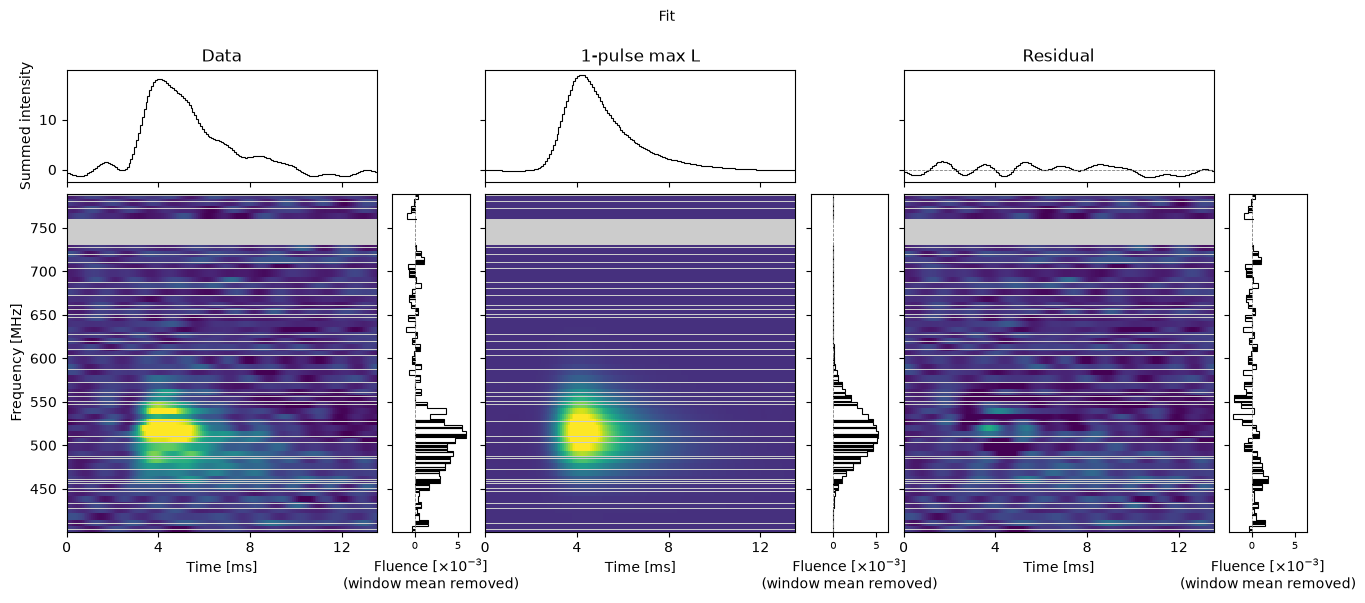

In [7]:
seed = None
res_1 = run_maxL(burst, single_pulse_fn, priors, n_pulses=1, num_starts=64, seed=seed,
                 tau_profile=8, tau_parallel=True, n_adam=1000, n_polish=500)
M, M_pulses = model_from_draw(single_pulse_fn, res_1["post"], 0)
plot_fit_TD(burst, M, M_pulses, title_model="1-pulse max L");

## 8. Finding the number of pulses automatically: `run_maxL_iterative`

With this method, a greedy search algorithm adds pulses one at a time to determine what number of pulses should be used to describe the significant signal features in the data:

1. Fit one pulse, as in step 7.
2. Look for signal the fit leaves behind: an excess-power search of the *residual* (data minus
   model) in boxes of channels × time. Leftover power counts only beyond what a 20% error in the
   model could produce (`epsilon`), and a box must be significant after allowing for the number of
   boxes searched (`p_false_alarm`). If no box is significant, stop.
3. Otherwise fit one more pulse, starting half the starts from the previous fit with the new pulse in
   a significant box (`n_warm`; `split_starts` and `box_spectrum` add starts that split an existing
   pulse in two, or give the new pulse a spectrum peaked in its box's band).
4. Keep the new pulse only if the log-likelihood rises by at least $\mathrm{snr_{min}}^2/2 + k$, where
   $k$ counts the parameters a new pulse adds, *and* the new pulse explains at least one of the boxes.
   Otherwise stop with the previous fit. Stop too at `n_max` pulses.

`snr_min` is the SNR of the weakest pulse worth adding. With `plot_steps=True` each step is plotted:
the boxes found in the residual, outlined in white where the new fit explains them, in red where it
does not, and dashed grey where the model barely changed. `repulsion={}` uses the repulsion prior's
default settings, `repulsion=None` turns it off. We strongly recommend keeping the repulsion prior on, to avoid overfitting.

run_maxL_iterative: up to 15 pulses, accept if ln L rises >= 37, seed 2; priors:
  mean_arrival_time: Uniform(low=0, high=0.0134349)
  DM: Uniform(low=-0.361228, high=0.361228)
  sigma: LogUniform(low=0.00023903, high=0.0022528)
  tau_ref: Uniform(low=0, high=0.00254446)
  gamma: Uniform(low=-277.259, high=277.259)
  beta: Uniform(low=-200, high=10)
  A_snr: HalfNormal(scale=100)
  delta: fixed at -4
  repulsion: x_min=1, w=0.05, K=1000, snr_on=3, w_snr=0.33, c_ratio=0, max_log_ratio=4, tau_scale=1, band_tau=True
run_maxL: likelihood FD_gaussianlikelihood, parameterizing fluence in units of SNR as A_snr, seed 2
run_maxL: 1 pulse(s), 64 starts (0 warm) x 9 tau values: best ln L + repulsion = -781.2 at tau_ref = 1.67e+03 µs (start 38, random); 30 start(s) within 1 nat; 13 s
Residual test (tolerating 20% model error): ADD A PULSE (p = 6e-12 after 4600 boxes; min_snr 8)
  3 feature(s) from 313 significant boxes; unexplained SNR [15.2, 8.7, 9.9]
split starts: 1 warm start(s) each split one 

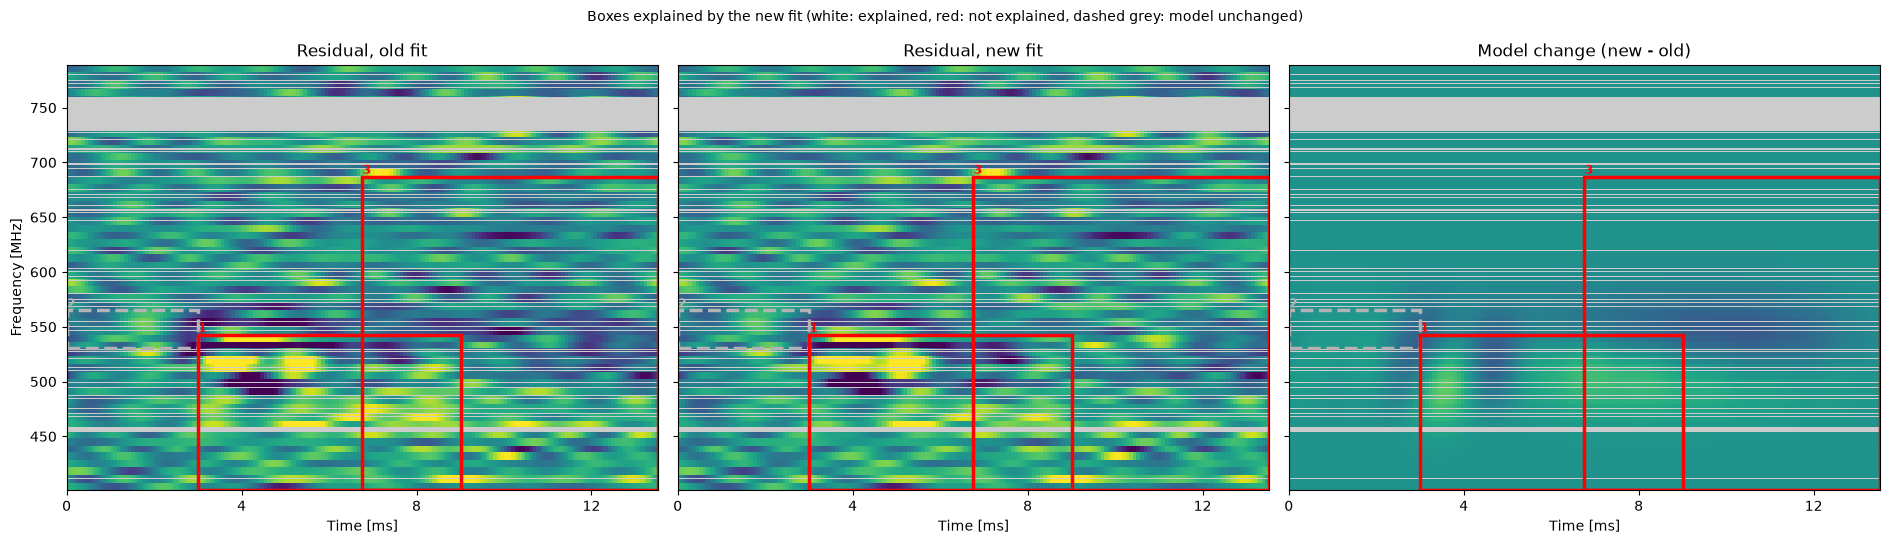

1 -> 2 pulses: delta ln L = 39.5 (need 37), explains leftover signal: False -> reject
final: 1 pulses (2-pulse fit rejected: it explains no significant leftover signal); optimizer time 38 s
rebaseline: each channel's noise-window mean subtracted, for display only.


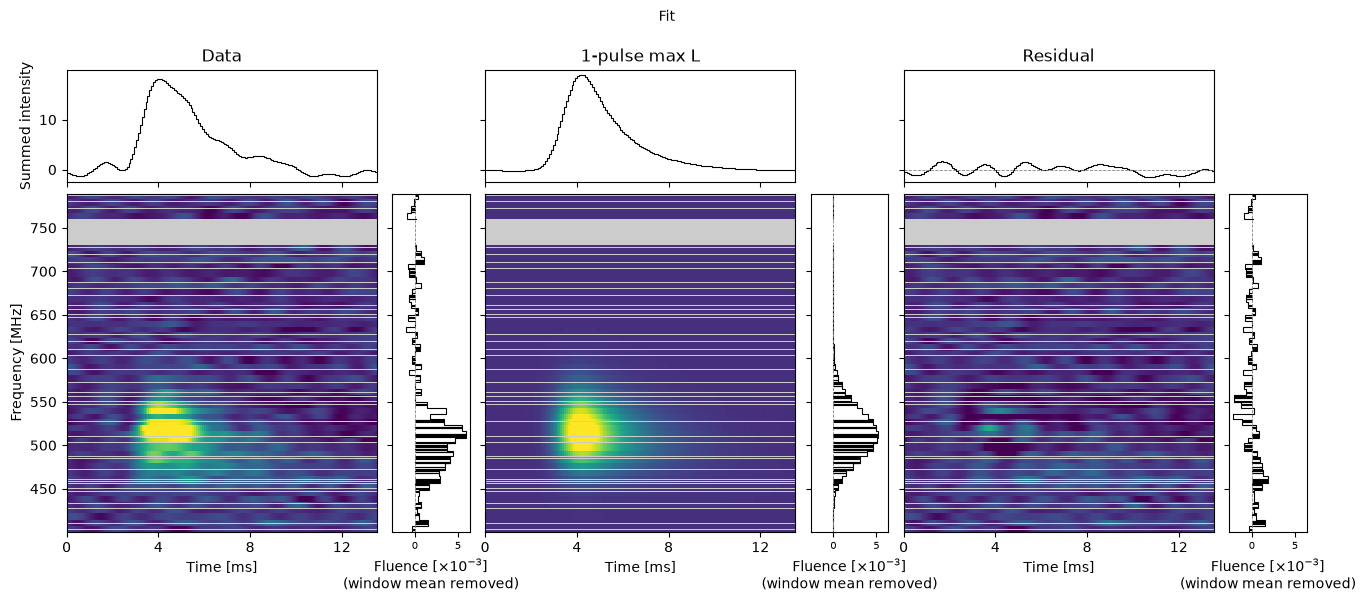

In [8]:
res_ml = run_maxL_iterative(
    burst, single_pulse_fn,
    snr_min=8.0, n_max=15, num_starts=64, seed=2, plot_steps=True,
    tau_profile=8, tau_parallel=True,                 # at least 8 tau values, 0.1 dt to the prior maximum
    n_adam=1000, n_polish=500,
    split_starts=True, box_spectrum=True,
    repulsion={},                                     # default repulsion settings
    s_opt=100.0, prior_kwargs={"band": BAND},         # the same priors as in step 6
)
M, M_pulses = model_from_draw(single_pulse_fn, res_ml["fit"]["post"], 0)
plot_fit_TD(burst, M, M_pulses, title_model=f"{res_ml['n_pulses']}-pulse max L");

### What the fit measures

Each fit returns the value of every parameter at its best point, in `res_ml["fit"]["map"]` (and
`res_1["map"]` for `run_maxL`). Per-pulse parameters are arrays with one value per pulse; shared ones
are single numbers.

| name | meaning | units | |
|---|---|---|---|
| `mean_arrival_time` | arrival time of the pulse's centre at $\nu_{\rm ref}$, from the start of the segment | s | per pulse |
| `sigma` | intrinsic width (standard deviation of the Gaussian) | s | per pulse |
| `DM_shared` | residual DM, on top of the DM the data were dedispersed with | pc cm⁻³ | shared |
| `tau_ref_shared` | scattering time $\tau_{\rm ref}$ at $\nu_{\rm ref}$ | s | shared |
| `gamma`, `beta` | spectral slope $\gamma$ and curvature $\beta$ at $\nu_{\rm ref}$ | | per pulse |
| `A_snr` | the pulse's signal-to-noise ratio | | per pulse |
| `A` | fluence at $\nu_{\rm ref}$ | data units × s | per pulse |
| `delta` | scattering index $\delta$, only when it is given a prior | | per pulse |

The other entries are helpers: `DM` and `tau_ref` repeat the shared values for each pulse,
`snr_opt` and `log_sed_peak` are internal scalings, and `toa_separation` is each pair of pulses'
separation in units of their combined widths, which the repulsion prior uses. The cell below shows
the best fit in readable units, with the pulses ordered by arrival time.

**Note on arrival times.** `mean_arrival_time` is measured from the start of the data segment, at
$\nu_{\rm ref}$, in the frame of the dedispersed data. FRBayes does not yet keep the segment's start
time, so it cannot convert arrival times to absolute times; this will be fixed in a later version.

In [9]:
import pandas as pd

best = {k: np.asarray(v)[0] for k, v in order_pulses(res_ml["fit"]["post"], verbose=False).items()}
n = res_ml["n_pulses"]
per_pulse = {"mean_arrival_time": (1e3, "ms"), "sigma": (1e3, "ms"), "gamma": (1.0, ""), "beta": (1.0, ""),
             "A_snr": (1.0, ""), "A": (1.0, "data units x s")}
shared = {"DM_shared": (1.0, "pc cm^-3"), "tau_ref_shared": (1e6, "us"), "delta": (1.0, "")}

table = pd.DataFrame({f"{k} [{u}]" if u else k: np.asarray(best[k], dtype=float) * s
                      for k, (s, u) in per_pulse.items() if k in best},
                     index=[f"pulse {j}" for j in range(n)])
for k, (s, u) in shared.items():
    if k in best:
        print(f"{k}: {float(best[k]) * s:.4g} {u}")
table

DM_shared: -0.01509 pc cm^-3
tau_ref_shared: 1672 us


,mean_arrival_time [ms],sigma [ms],gamma,beta,A_snr,A [data units x s]
pulse 0,3.514149,0.567586,-2.448395,-149.490143,75.33564,0.005449


## 9. The posterior: `run_NUTS`

The maximum-likelihood fit is one best point. The *posterior* is the full distribution of parameter
values consistent with the data and priors; NUTS (the No-U-Turn Sampler) draws samples from it. Each
*chain* is an independent sampler: it spends `num_warmup` steps tuning itself, then keeps
`num_samples` draws. Here every chain has a *warm start* at the search's best fit (`maxL_start`), with the same
number of pulses, priors and likelihood settings.

Warm starts are extremely important for FRBayes to perform Bayesian sampling properly, and we do not
recommend running NUTS without a warm start. The likelihood for our FRB data often has many separate peaks, and at the high
SNRs of most bursts the valleys between the peaks are too deep for a chain to cross, so chains started
at random rarely reach the best fit by themselves. Besides warm starting with the iterative fit result,
one could start with a specific `run_maxL` result (`maxL_start=res_1`, with `res_1["priors"]`).
Initializing the sampler with random points is also possible (`n_pulses=...` without `maxL_start`),
but highly discouraged.

Other running choices include `shared_params` (which parameters all pulses share). Read the source
code to see more.

In [10]:
mcmc = run_NUTS(burst, single_pulse_fn, res_ml["fit"]["priors"], maxL_start=res_ml,
                num_chains=64, num_warmup=500, num_samples=200, seed=2, repulsion={})

run_NUTS: likelihood FD_gaussianlikelihood, parameterizing fluence in units of SNR as A_snr, seed 2; priors as in the maxL fit
  delta: fixed at -4
  repulsion: x_min=1, w=0.05, K=1000, snr_on=3, w_snr=0.33, c_ratio=0, max_log_ratio=4, tau_scale=1, band_tau=True


sample: 100%|██████████| 700/700 [00:40<00:00, 17.12it/s] 


## 10. Look at the posterior

Every chain is kept, with an implicit assumption that the posterior has a single peak (*mode*) that all chains sample. In
every draw the pulses are numbered by arrival time (0 = earliest), so pulse 0 means the same pulse in
every chain. `group_chains` checks the single-mode assumption: chains that disagree are printed as
separate modes. Since every chain starts at the same best fit, a pass means the chains agree around
that fit, not that no other mode exists.

The corner plot shows one pulse's parameters with the shared ones, and the trace plot each chain's
draws in turn, one colour per chain: chains sampling the same mode overlap. In the summary table,
`r_hat` compares the chains (close to 1, below about 1.01, when they agree) and `ess_bulk`,
`ess_tail` estimate how many independent draws the chains are worth.

group_chains: 64 chains -> 1 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63], largest R-hat within 1.052
64 chains x 200 draws


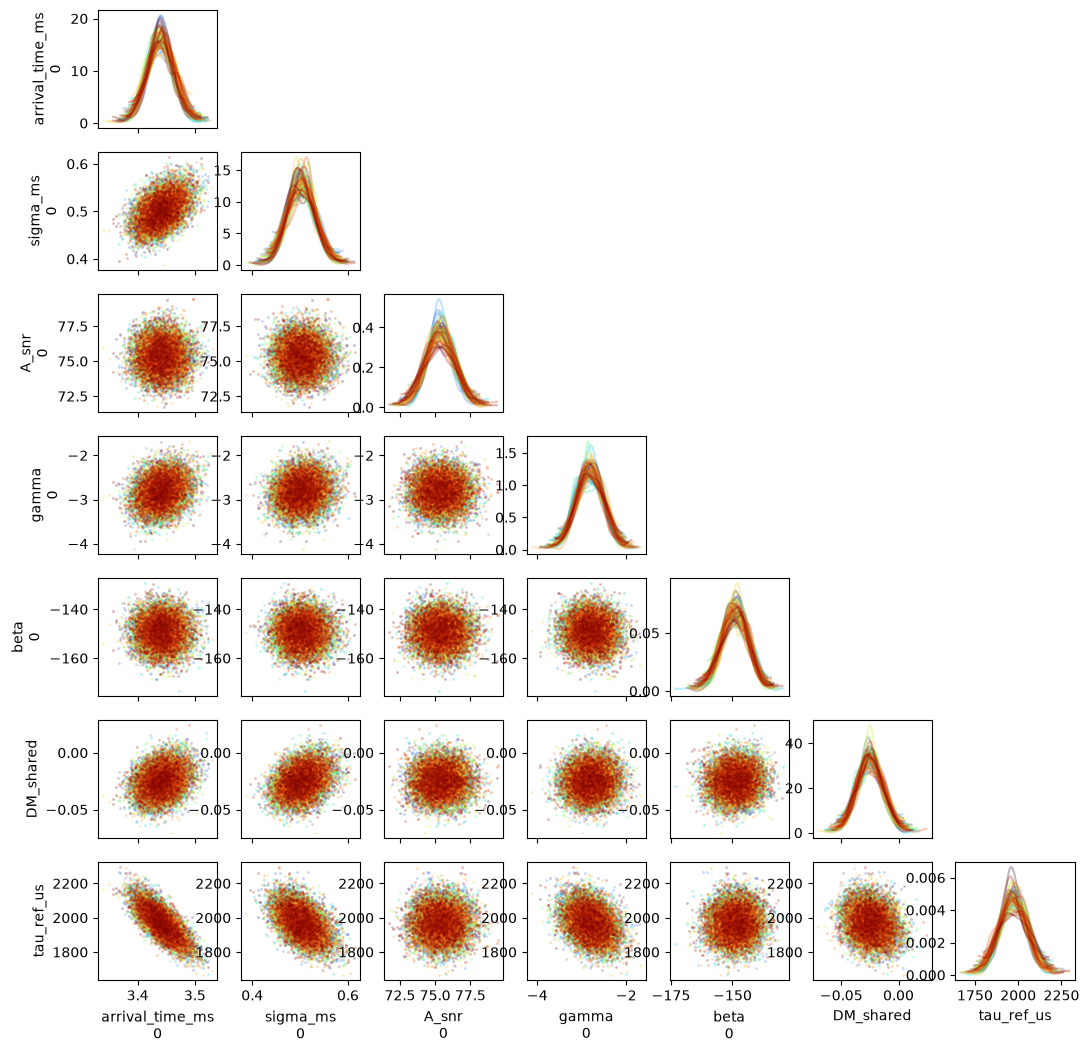

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.005818,0.000159,0.0056,0.0061,12038,9523,1.01,1.5e-06,1.5e-06
A_snr[0],75.38,1.01,74,77,13331,10367,1.00,0.0088,0.0091
DM_shared,-0.0248,0.0115,-0.043,-0.0063,12012,9893,1.00,0.0001,9.8e-05
beta[0],-149,5.42,-160,-140,11749,9158,1.00,0.05,0.045
gamma[0],-2.811,0.305,-3.3,-2.3,14796,10938,1.00,0.0025,0.0024
log_sed_peak[0],0.01139,0.00182,0.0085,0.014,14710,10804,1.00,1.5e-05,1.5e-05
arrival_time_ms[0],3.4408,0.0236,3.4,3.5,14501,10797,1.00,0.0002,0.00019
sigma_ms[0],0.5025,0.0292,0.46,0.55,11594,8843,1.00,0.00027,0.00024
snr_opt[0],12818,309,12000,13000,11318,8866,1.00,2.9,2.7
tau_ref_us,1972,82,1800,2100,11307,8489,1.00,0.77,0.73


In [11]:
run = mcmc                # a run_NUTS result
PULSE = 0                 # which pulse to plot (0 = earliest)

# Every chain is kept; each draw's pulses are ordered by arrival time
n = run.n_pulses
s = order_pulses({k: np.asarray(v) for k, v in run.get_samples(group_by_chain=True).items()}, verbose=False)

# Check of the single-mode assumption: chains that disagree (pairwise R-hat above 1.1) are printed as separate modes
group_chains(s, pointwise_log_lik(burst, single_pulse_fn, s, thin=1))

# All chains, in readable units, keeping the chain axis for R-hat and ESS
units = {"mean_arrival_time": ("arrival_time_ms", 1e3), "sigma": ("sigma_ms", 1e3), "tau_ref": ("tau_ref_us", 1e6)}
data, dims = {}, {}
for k, v in s.items():
    v = np.asarray(v, dtype=float)
    if (not k.endswith("_shared") and f"{k}_shared" in s) or k in PAIR_SITES:
        continue                           # copies of shared parameters, and pair sites like toa_separation
    name, unit = units.get(k.removesuffix("_shared"), (k, 1.0))
    data[name] = v * unit
    if v.ndim == 3:
        dims[name] = ["pulse"]
dt = az.from_dict({"posterior": data}, dims=dims, coords={"pulse": np.arange(n)})
n_chains = dt.posterior.sizes["chain"]
print(f"{n_chains} chains x {dt.posterior.sizes['draw']} draws")

# Corner plot of one pulse with the shared parameters, one colour per chain
pulse_vars = [v for v in ["arrival_time_ms", "sigma_ms", "A_snr", "gamma", "beta", "delta"] if v in dt.posterior]
shared_vars = [v for v in ["DM_shared", "tau_ref_us"] if v in dt.posterior]
names = pulse_vars + shared_vars
colours = [to_hex(c) for c in plt.cm.turbo(np.linspace(0, 1, max(n_chains, 3)))]   # arviz_plots needs at least 3
arviz_base.rcParams["plot.max_subplots"] = 300
azp.plot_pair(dt, var_names=names, coords={"pulse": [PULSE]}, marginal=True, triangle="lower",
              aes={"color": ["chain"]}, aes_by_visuals={"scatter": ["color"], "dist": ["color"]},
              color=colours, visuals={"scatter": {"alpha": 0.3, "size": 4}, "dist": {"alpha": 0.3}},
              figure_kwargs={"figsize": (1.8 * len(names), 1.8 * len(names))})
plt.show()

az.summary(dt, kind="all")

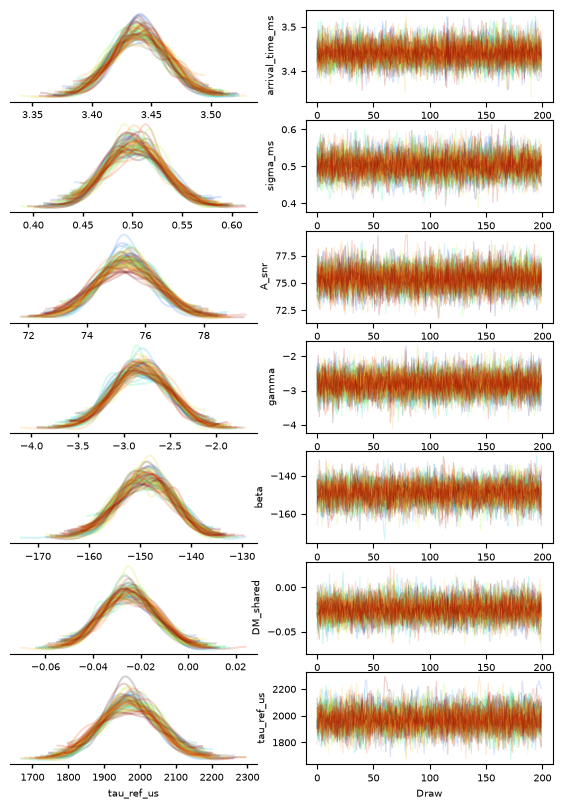

In [12]:
# Trace of every chain, one colour per chain: chains sampling the same mode overlap, separate ones sit apart
with plt.rc_context({"font.size": 7}):
    azp.plot_trace_dist(dt, var_names=names, coords={"pulse": [PULSE]}, compact=True,
                        aes={"color": ["chain"]}, aes_by_visuals={"trace": ["color"], "dist": ["color"]},
                        color=colours,
                        visuals={"trace": {"alpha": 0.2, "linewidth": 0.8}, "dist": {"alpha": 0.2}},
                        figure_kwargs={"figsize": (7, 1.4 * len(names))})
    plt.show()

### Working with the samples

The result of the fit is the whole posterior: the set of draws, which together carry each
parameter's uncertainty and every correlation between parameters (between a pulse's width and the
scattering time, for example). A median and an interval for each parameter on its own throw those
correlations away, so use the draws themselves: compute any derived quantity draw by draw, from the
parameters of the same draw, so that the result is itself a posterior.

`mcmc.get_samples()` returns one array per *site* (each quantity the model records), with the
chains pooled; `group_by_chain=True` keeps them apart, with a leading chain axis. Order the pulses
by arrival time first, as below, so that pulse 0 is the same pulse in every draw. The cell prints
every site with its shape and kind:

- **Per pulse**, shape (draws, pulses): `mean_arrival_time`, `sigma`, `gamma`, `beta`, `A_snr`, and
  `A`, the fluence, computed from `A_snr`; also `delta` when it is given a prior.
- **Shared**, shape (draws,): one value per draw for the whole burst, `DM_shared` and
  `tau_ref_shared` by default (`shared_params` in step 9 sets which). Draw $i$ of a shared site
  belongs with draw $i$ of every per-pulse site, so pair them by index. Each shared parameter is also
  recorded under its plain name (`DM`, `tau_ref`), repeated for every pulse, so that code working
  pulse by pulse need not treat it differently; these copies hold nothing new, so use the `_shared`
  site and do not count the copies as separate measurements. A parameter that is not shared has only
  its plain, per-pulse site.
- **Bookkeeping**, not measurements of the burst: `snr_opt` and `log_sed_peak`, internal scalings
  that convert `A_snr` to `A`, and `toa_separation`, each pair of pulses' separation in units of
  their combined widths, which the repulsion prior uses (shape (draws, pairs)). They are recorded
  because the fit uses them, and can be ignored for science.

The arrival times, $\tau_{\rm ref}$, $\gamma$, $\beta$ and the fluence are all defined at the reference
frequency $\nu_{\rm ref}$, which differs from burst to burst, so quote it with them: it is
`burst.freq_channels_ref`, in MHz, printed first below. The end of the cell builds two posteriors
from the draws as examples: the total DM, the dedispersion DM plus the residual, and the joint draws
of one pulse's width and the shared scattering time.

In [13]:
print(f"nu_ref = {burst.freq_channels_ref:.3f} MHz")     # the reference frequency of the fit, from the burst object

# Pulse 0 is the earliest pulse in every draw
samples = {k: np.asarray(v) for k, v in order_pulses(mcmc.get_samples(), verbose=False).items()}

BOOKKEEPING = ("snr_opt", "log_sed_peak", *PAIR_SITES)  # recorded because the fit uses them, not measurements
print()
for name, v in samples.items():
    if name in BOOKKEEPING:
        kind = "bookkeeping"
    elif name.endswith("_shared"):
        kind = "shared"
    elif f"{name}_shared" in samples:
        kind = f"copy of {name}_shared, repeated per pulse"
    else:
        kind = "per pulse"
    print(f"{name:18s} {str(v.shape):12s} {kind}")

# Derived quantities, draw by draw, so each is a posterior in its own right
if burst.dm_dedispersion is not None:
    DM_total = burst.dm_dedispersion + samples["DM_shared"]                        # (draws,)
    print(f"\nDM_total: {DM_total.shape[0]} draws of the total DM (pc cm^-3)")
width_tau = np.column_stack([samples["sigma"][:, PULSE], samples["tau_ref_shared"]])   # (draws, 2), paired by draw
print(f"pulse {PULSE} sigma with tau_ref: {width_tau.shape[0]} joint draws (s), "
      f"correlation {np.corrcoef(width_tau.T)[0, 1]:+.2f}")

nu_ref = 515.698 MHz

A                  (12800, 1)   per pulse
A_snr              (12800, 1)   per pulse
DM                 (12800, 1)   copy of DM_shared, repeated per pulse
DM_shared          (12800,)     shared
beta               (12800, 1)   per pulse
gamma              (12800, 1)   per pulse
log_sed_peak       (12800, 1)   bookkeeping
mean_arrival_time  (12800, 1)   per pulse
sigma              (12800, 1)   per pulse
snr_opt            (12800, 1)   bookkeeping
tau_ref            (12800, 1)   copy of tau_ref_shared, repeated per pulse
tau_ref_shared     (12800,)     shared

DM_total: 12800 draws of the total DM (pc cm^-3)
pulse 0 sigma with tau_ref: 12800 joint draws (s), correlation -0.50


## 11. Save the result

`save_run` writes the posterior draws, the priors, the model's settings and a reference to the data
file (its path and a hash of its contents, not the data itself) to a netCDF file. It needs two facts
about how the data were dedispersed before FRBayes: the DM used, since the fitted DM is only the
residual on top of it (the saved posterior gets `DM_total`, their sum), and the frequency the channels
were aligned to, which converts fitted arrival times to the telescope's clock. `prepare_burst` reads
both from the burst's `.npz` (keys `dm_dedispersion` and `dedispersion_ref_freq`) when the file has
them; otherwise give them to `save_run` as arguments of the same names. The cell below skips saving
if the file does not have them.

`load_run` reads a saved fit back, and `check_data_unchanged` confirms that a data file is the one
the fit was made on. The reference frequency is saved too, as the posterior's attribute
`freq_channels_ref`.

In [14]:
out_path = Path("runs") / f"event_{event_id}.nc"
if burst.dm_dedispersion is None or burst.dedispersion_ref_freq is None:
    print("not saved: this burst's .npz does not record its dedispersion DM and frequency")
else:
    out_path.parent.mkdir(parents=True, exist_ok=True)
    save_run(out_path, mcmc, burst, res_ml["fit"]["priors"], single_pulse_fn=single_pulse_fn,
             n_pulses=res_ml["n_pulses"])
    saved = load_run(out_path)
    print("saved to", out_path, "; data file unchanged:", check_data_unchanged(saved, DATA / f"event_{event_id}.npz"))
    print("nu_ref from the saved file:", float(saved["posterior"].attrs["freq_channels_ref"]), "MHz")

saved to runs/event_23438043_BB.nc ; data file unchanged: True
nu_ref from the saved file: 515.697815 MHz


## Known limitations

The likelihood assumes the noise is white, stationary and known exactly, with no self-noise from the
burst itself; on bright bursts this makes uncertainties too small and can lower the bar for adding
pulses. Check every fit against the plots. The README lists the known limitations.